In [3]:
pip install opencv-python 


   ---------------------------------------- 0.0/40.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/40.2 MB ? eta -:--:--
    --------------------------------------- 0.5/40.2 MB 2.6 MB/s eta 0:00:16
   -- ------------------------------------- 2.9/40.2 MB 7.8 MB/s eta 0:00:05
   ---- ----------------------------------- 4.2/40.2 MB 9.6 MB/s eta 0:00:04
   -------- ------------------------------- 8.4/40.2 MB 12.4 MB/s eta 0:00:03
   ------------ --------------------------- 12.6/40.2 MB 12.9 MB/s eta 0:00:03
   ----------------- ---------------------- 17.8/40.2 MB 15.0 MB/s eta 0:00:02
   ---------------------- ----------------- 22.5/40.2 MB 16.2 MB/s eta 0:00:02
   ------------------------- -------------- 25.4/40.2 MB 16.6 MB/s eta 0:00:01
   ------------------------------ --------- 30.4/40.2 MB 16.8 MB/s eta 0:00:01
   ---------------------------------- ----- 34.6/40.2 MB 17.2 MB/s eta 0:00:01
   -------------------------------------- - 38.8/40.2 MB 17.5 MB/s eta 0:00:0

In [4]:
pip install 'numpy<2'

Note: you may need to restart the kernel to use updated packages.


The system cannot find the file specified.


In [7]:
pip install matplolib

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement matplolib (from versions: none)
ERROR: No matching distribution found for matplolib


In [6]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

def show(img, title=None, cmap=None):
    plt.figure(figsize=(6,4))
    if img.ndim == 2:
        plt.imshow(img, cmap=cmap or "gray")
    else:
        plt.imshow(img)  # assume already RGB
    if title:
        plt.title(title)
    plt.axis("off")
    plt.show()


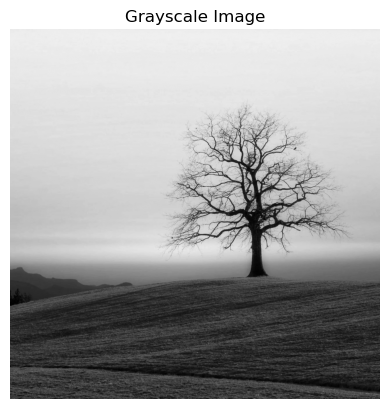

In [10]:
image_data = cv2.imread('C:/Users/Abror/Desktop/img.png', 0)

plt.imshow(image_data, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

In [11]:
image_data.shape

(1280, 1280)

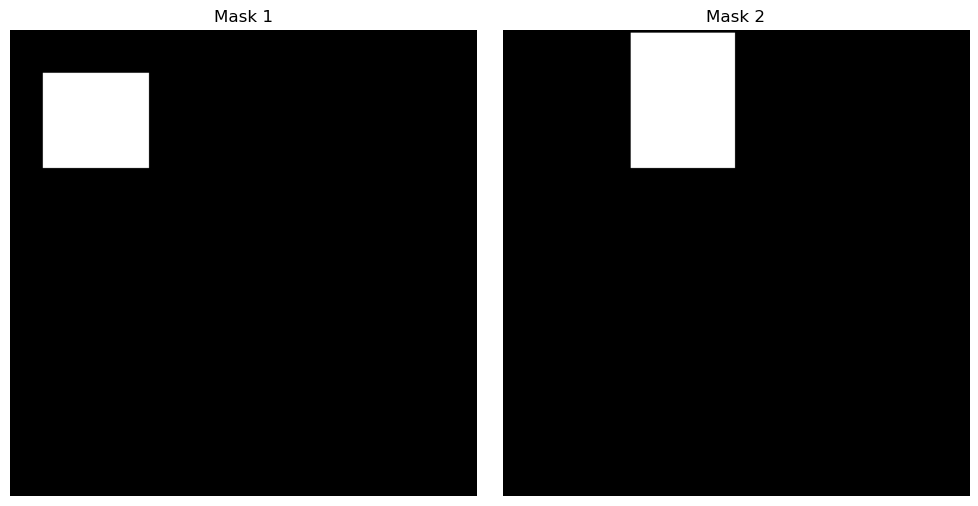

In [12]:
mask1 = np.zeros(image_data.shape[:2], np.uint8)
mask2 = np.zeros(image_data.shape[:2], np.uint8)

cv2.rectangle(mask1, (90, 120), (380, 380), 255, -1)
cv2.rectangle(mask2, (350, 10), (635, 380), 255, -1)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(mask1, cmap='gray')
plt.title("Mask 1")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(mask2, cmap='gray')
plt.title("Mask 2")
plt.axis("off")

plt.tight_layout()
plt.show()

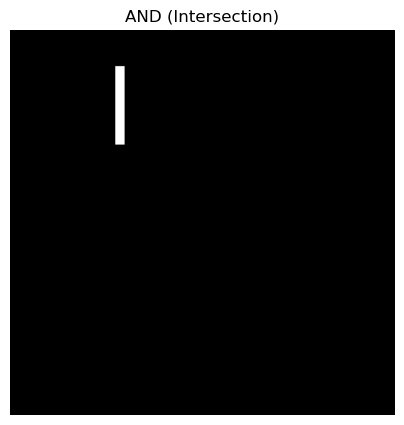

In [13]:
And = cv2.bitwise_and(mask1, mask2)

plt.figure(figsize=(5,5))
plt.imshow(And, cmap='gray')
plt.title("AND (Intersection)")
plt.axis("off")
plt.show()

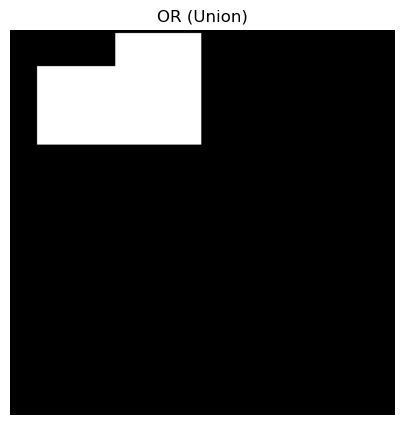

In [14]:
bitwiseOr = cv2.bitwise_or(mask1, mask2)

plt.figure(figsize=(5,5))
plt.imshow(bitwiseOr, cmap='gray')
plt.title("OR (Union)")
plt.axis("off")
plt.show()

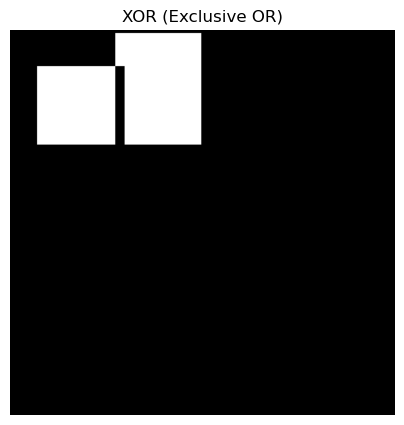

In [15]:
bitwiseXor = cv2.bitwise_xor(mask1, mask2)

plt.figure(figsize=(5,5))
plt.imshow(bitwiseXor, cmap='gray')
plt.title("XOR (Exclusive OR)")
plt.axis("off")
plt.show()

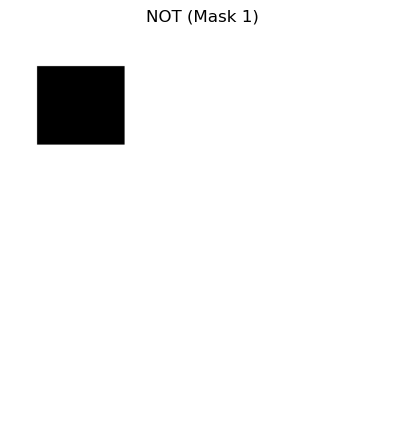

In [16]:
bitwiseNot_sq = cv2.bitwise_not(mask1)

plt.figure(figsize=(5,5))
plt.imshow(bitwiseNot_sq, cmap='gray')
plt.title("NOT (Mask 1)")
plt.axis("off")
plt.show()

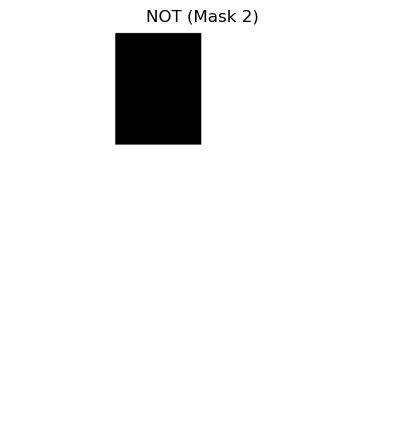

In [17]:
bitwiseNot_ell = cv2.bitwise_not(mask2)

plt.figure(figsize=(5,5))
plt.imshow(bitwiseNot_ell, cmap='gray')
plt.title("NOT (Mask 2)")
plt.axis("off")
plt.show()

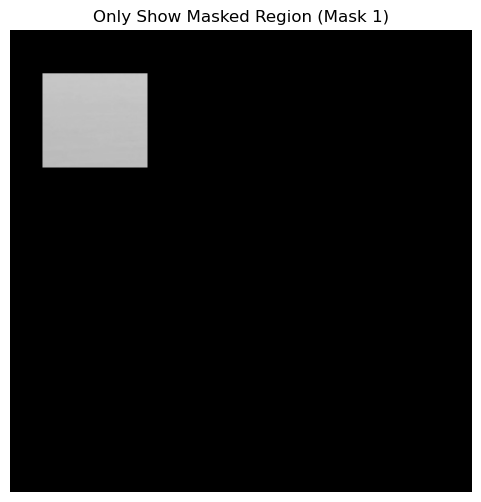

In [18]:
puppy = cv2.bitwise_and(image_data, image_data, mask=mask1)

puppy_rgb = cv2.cvtColor(puppy, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6,6))
plt.imshow(puppy_rgb)
plt.title("Only Show Masked Region (Mask 1)")
plt.axis("off")
plt.show()

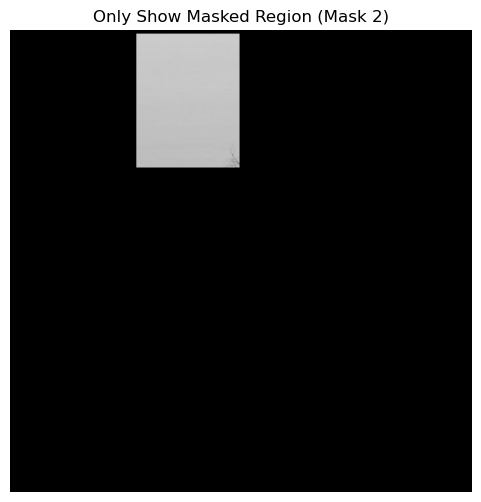

In [19]:
dog = cv2.bitwise_and(image_data, image_data, mask=mask2)

dog_rgb = cv2.cvtColor(dog, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6,6))
plt.imshow(dog_rgb)
plt.title("Only Show Masked Region (Mask 2)")
plt.axis("off")
plt.show()

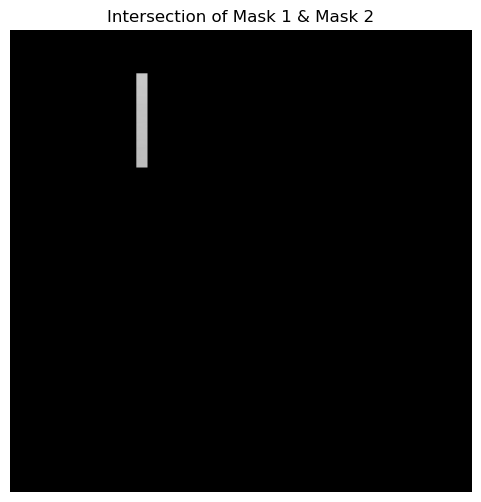

In [20]:
dog = cv2.bitwise_and(image_data, image_data, mask=And)

dog_rgb = cv2.cvtColor(dog, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6,6))
plt.imshow(dog_rgb)
plt.title("Intersection of Mask 1 & Mask 2")
plt.axis("off")
plt.show()
     

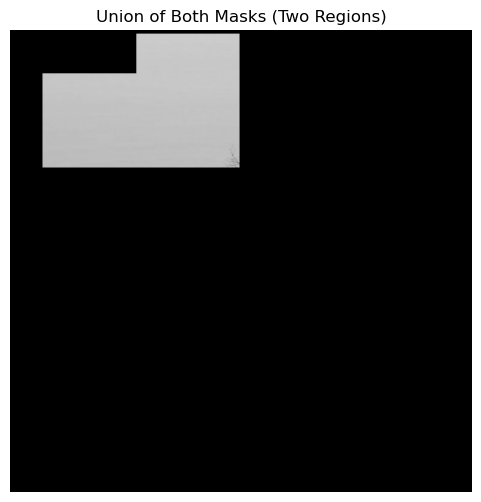

In [21]:
dog = cv2.bitwise_and(image_data, image_data, mask=bitwiseOr)

dog_rgb = cv2.cvtColor(dog, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6,6))
plt.imshow(dog_rgb)
plt.title("Union of Both Masks (Two Regions)")
plt.axis("off")
plt.show()


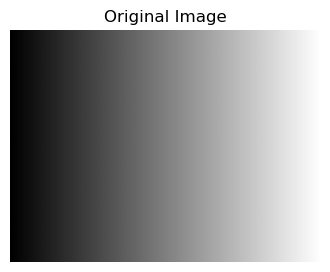

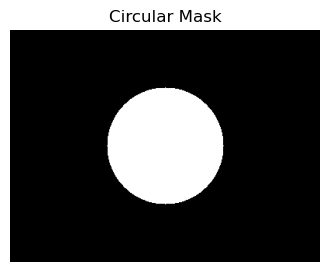

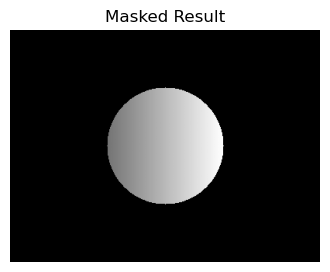

In [22]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

def show(img, title="", cmap=None):
    plt.figure(figsize=(4,4))
    plt.imshow(img, cmap=cmap)
    plt.title(title)
    plt.axis("off")
    plt.show()

img = np.tile(np.linspace(0, 255, 400, dtype=np.uint8), (300, 1))

h, w = img.shape

mask = np.zeros((h, w), dtype=np.uint8)

cx, cy = w // 2, h // 2
r = min(h, w) // 4

cv2.circle(mask, (cx, cy), r, 255, -1)

masked = cv2.bitwise_and(img, img, mask=mask)

show(img, "Original Image", cmap="gray")
show(mask, "Circular Mask", cmap="gray")
show(masked, "Masked Result", cmap="gray")

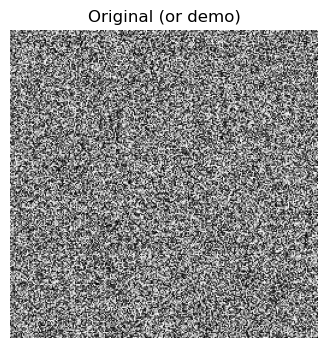

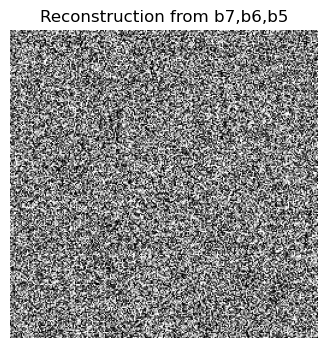

In [23]:
img = (np.random.rand(256,256)*255).astype(np.uint8)

planes = [(img >> i) & 1 for i in range(8)]

recon = np.zeros_like(img, dtype=np.uint8)
for i in [7,6,5]:
    recon = recon + (planes[i].astype(np.uint8) << i)

show(img, "Original (or demo)", cmap="gray")
show(recon, "Reconstruction from b7,b6,b5", cmap="gray")

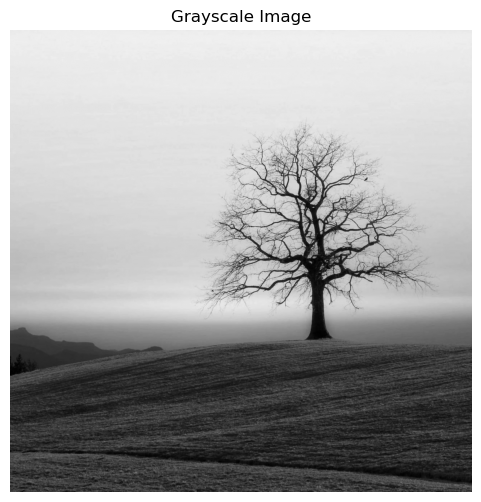

In [24]:
img = cv2.imread('C:/Users/Abror/Desktop/img.png', 0)

plt.figure(figsize=(6,6))
plt.imshow(img, cmap='gray')
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

Text(0, 0.5, 'Frequency')

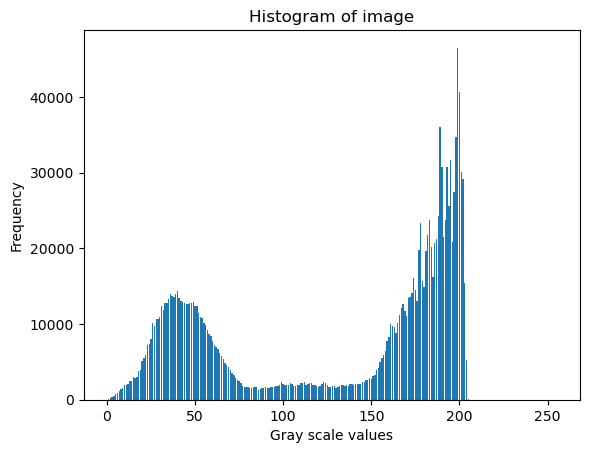

In [25]:
hist = cv2.calcHist(images=[img], channels=[0], mask=None, histSize=[256], ranges=[0, 255])

plt.bar(range(256), hist.ravel())
plt.title('Histogram of image')
plt.xlabel('Gray scale values')
plt.ylabel('Frequency')

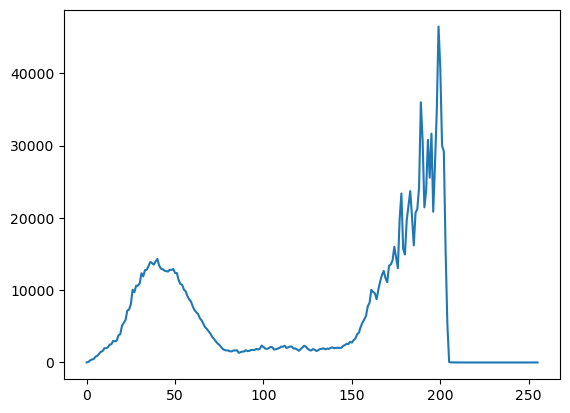

In [26]:
hist,bins = np.histogram(img.ravel(),256,[0,256])
plt.plot(hist)

In [31]:
high = cv2.imread('C:/Users/Abror/Desktop/img.png')
low = cv2.imread('C:/Users/Abror/Desktop/image.webp')

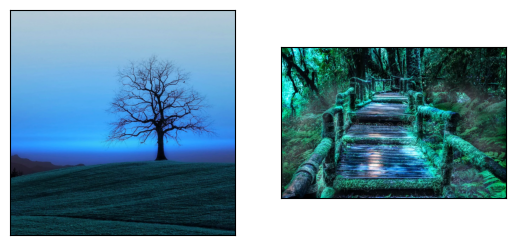

In [32]:
plt.subplot(121), plt.imshow(high)
plt.grid(False), plt.xticks([]), plt.yticks([])

plt.subplot(122), plt.imshow(low)
plt.grid(False), plt.xticks([]), plt.yticks([])
plt.show()

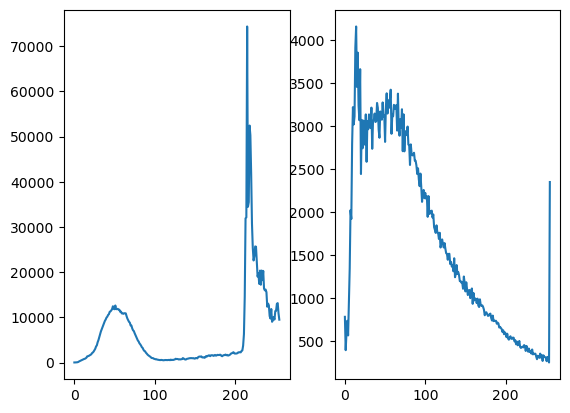

In [34]:
hist_high = cv2.calcHist([high],[2],None,[256],[0,256])
hist_low = cv2.calcHist([low],[2],None,[256],[0,256])

plt.subplot(121)
plt.plot(hist_high)

plt.subplot(122)
plt.plot(hist_low)

plt.show()

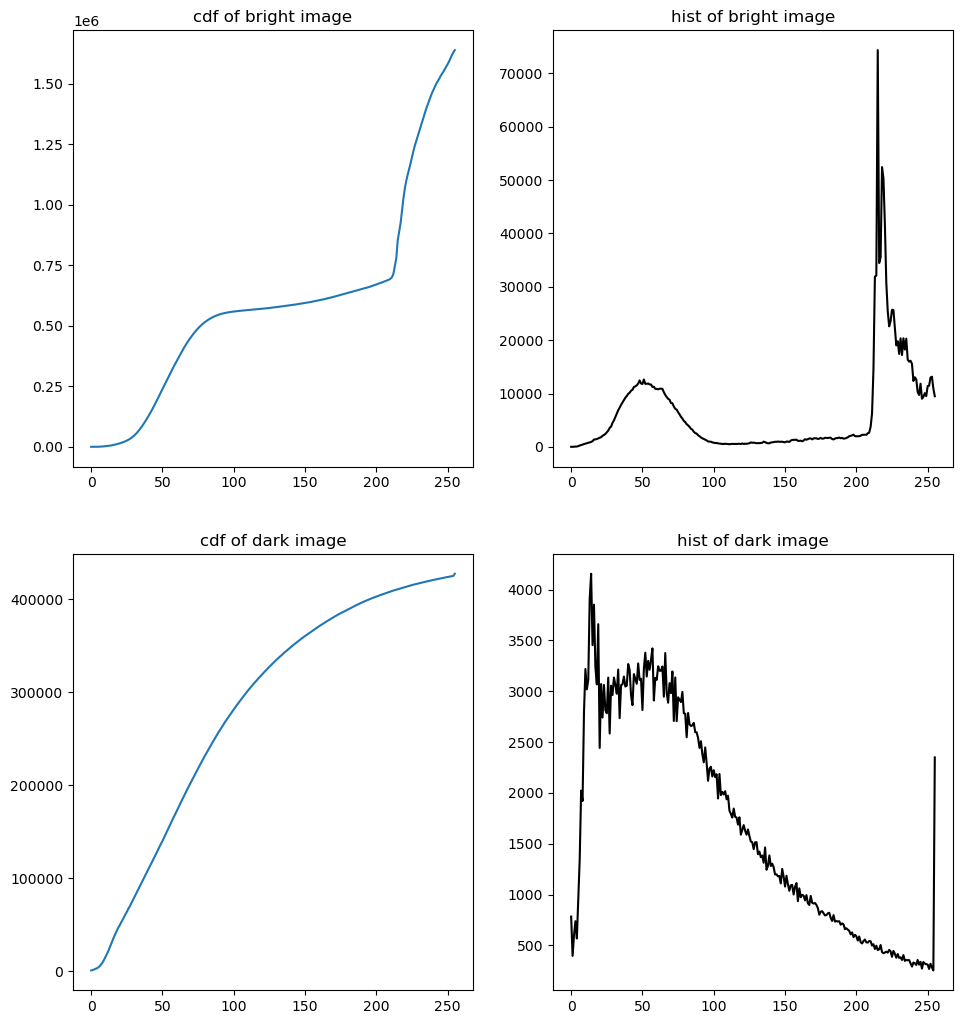

In [35]:
cdf_low = hist_low.cumsum()
cdf_high = hist_high.cumsum()

plt.subplot(221), plt.plot(cdf_high), plt. title('cdf of bright image')
plt.subplot(222), plt.plot(hist_high, 'k'), plt. title('hist of bright image')

plt.subplot(223), plt.plot(cdf_low), plt. title('cdf of dark image')
plt.subplot(224), plt.plot(hist_low, 'k'), plt. title('hist of dark image')

plt.subplots_adjust(bottom=1, right=1.5, top=3)

plt.show()

In [36]:

low_gray = cv2.cvtColor(low, cv2.COLOR_BGR2GRAY)
high_gray = cv2.cvtColor(high, cv2.COLOR_BGR2GRAY)

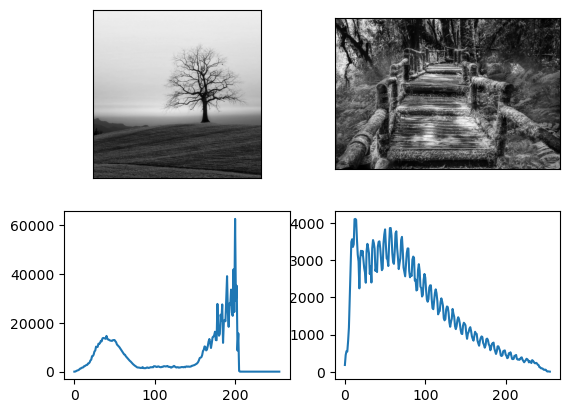

In [37]:
plt.subplot(221), plt.imshow(high_gray, cmap='gray')
plt.grid(False), plt.xticks([]), plt.yticks([])
plt.subplot(223), plt.plot(cv2.calcHist([high_gray],[0],None,[256],[0,256]))

plt.subplot(222), plt.imshow(low_gray, cmap='gray')
plt.grid(False), plt.xticks([]), plt.yticks([])
plt.subplot(224), plt.plot(cv2.calcHist([low_gray],[0],None,[256],[0,256]))

plt.show()

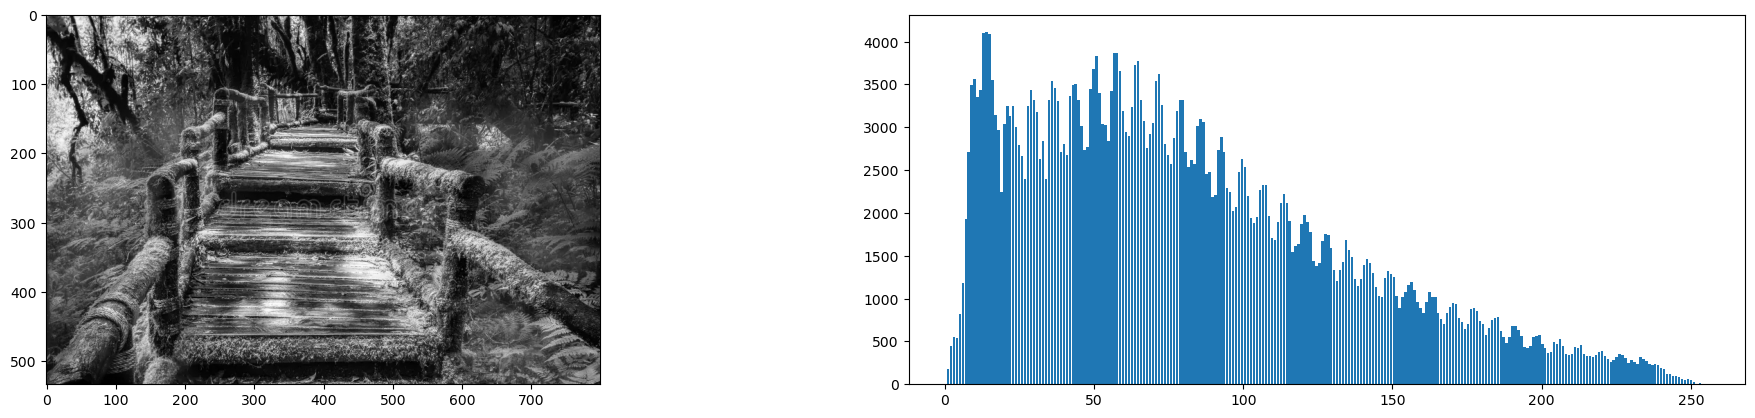

In [38]:
img = cv2.imread('C:/Users/Abror/Desktop/image.webp', 0)
img_hist = np.histogram(img, bins=256)

plt.subplot(121), plt.imshow(img, cmap='gray')
plt.subplot(122), plt.bar(img_hist[1][1:], img_hist[0])
plt.subplots_adjust(right=3)
plt.show()
     

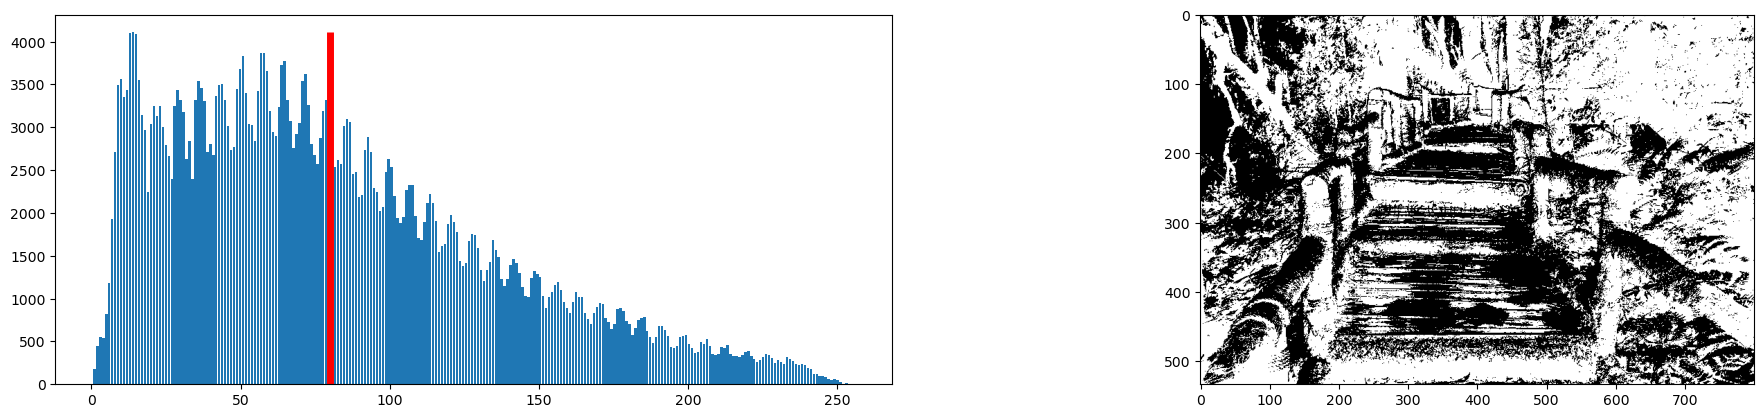

[False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True False False False False  True False False False False
 False False False False False  True  True  True False False False False
 False False False False False False False False False False False False
 False False False False  True  True  True  True  True  True False  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True False  True  True  True  True False False
  True  True  True  True  True False False False False False  True  True
 False  True  True  True False  True  True False  T

In [39]:
t = 80
thresholded = img < t

plt.subplot(121)
plt.bar(img_hist[1][1:], img_hist[0])
plt.vlines(t, 0, np.amax(img_hist[0]), colors='r', linewidth=5)
plt.subplot(122)
plt.imshow(thresholded, cmap="gray")
plt.subplots_adjust(right=3)
plt.show()

print(thresholded[150])

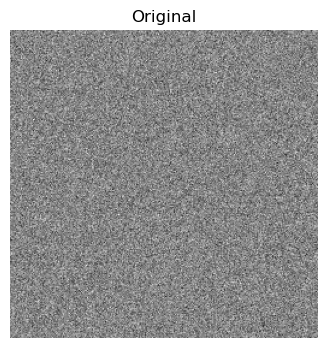

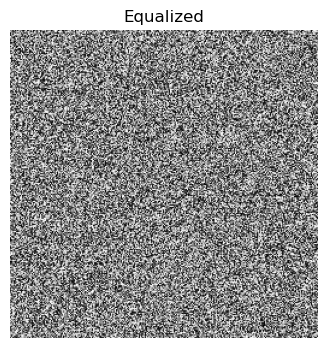

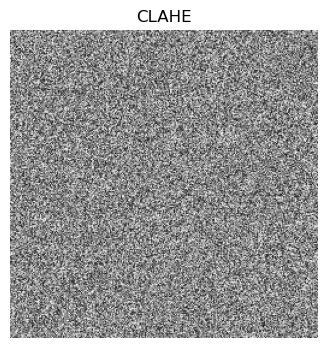

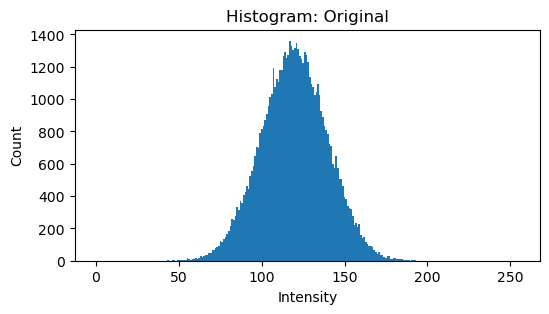

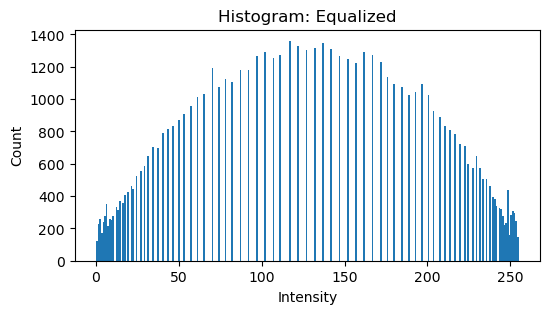

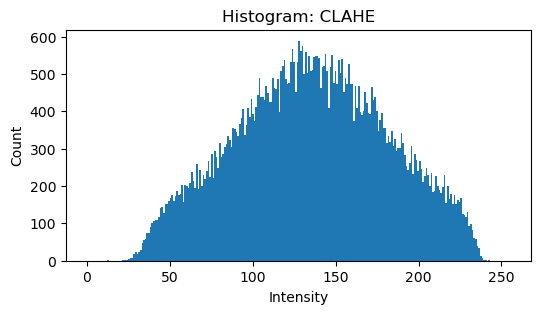

In [40]:
img = np.uint8(np.clip(120 + 20*np.random.randn(256,256), 0, 255))

eq = cv2.equalizeHist(img)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8)).apply(img)

def plot_hist(a, title):
    plt.figure(figsize=(6,3))
    plt.hist(a.ravel(), bins=256, range=(0,255))
    plt.title(title)
    plt.xlabel("Intensity")
    plt.ylabel("Count")
    plt.show()

show(img, "Original", cmap="gray")
show(eq, "Equalized", cmap="gray")
show(clahe, "CLAHE", cmap="gray")

plot_hist(img, "Histogram: Original")
plot_hist(eq, "Histogram: Equalized")
plot_hist(clahe, "Histogram: CLAHE")


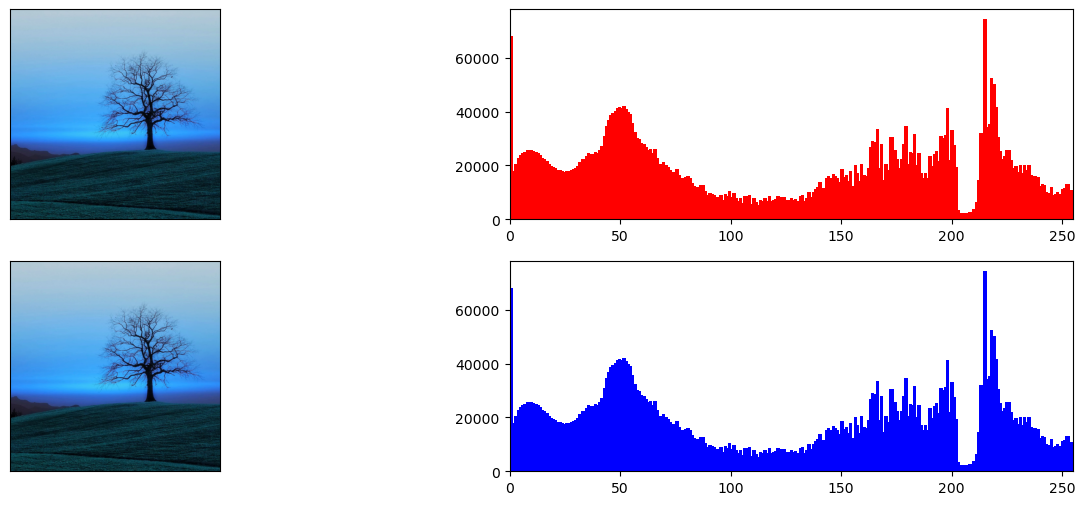

[[[177. 201. 207.]
  [177. 201. 207.]
  [177. 201. 207.]
  ...
  [179. 202. 204.]
  [179. 203. 203.]
  [179. 203. 203.]]

 [[177. 201. 207.]
  [177. 201. 207.]
  [177. 201. 207.]
  ...
  [179. 202. 204.]
  [179. 202. 204.]
  [179. 203. 203.]]

 [[177. 200. 208.]
  [177. 200. 208.]
  [177. 200. 208.]
  ...
  [179. 202. 204.]
  [179. 202. 204.]
  [179. 202. 204.]]

 ...

 [[ 11.  57.  64.]
  [ 17.  63.  70.]
  [ 21.  67.  74.]
  ...
  [ 10.  45.  58.]
  [  0.  32.  45.]
  [  0.  31.  44.]]

 [[ 16.  62.  69.]
  [ 21.  67.  74.]
  [ 21.  69.  75.]
  ...
  [ 13.  48.  58.]
  [  2.  31.  45.]
  [  6.  33.  47.]]

 [[  5.  51.  58.]
  [  9.  55.  62.]
  [  8.  56.  62.]
  ...
  [ 17.  49.  60.]
  [  9.  36.  50.]
  [ 16.  42.  56.]]]


In [41]:
image = cv2.imread('C:/Users/Abror/Desktop/img.png')
hist_img = np.histogram(image, bins=256)

stretched_img = (255 - 0) / (np.amax(image) - np.amin(image)) * (image - np.amin(image))
hist_strch = np.histogram(stretched_img, bins=256)

plt.figure(figsize=(16, 6))
plt.subplot(221), plt.xticks([]), plt.yticks([])
plt.imshow(image, cmap='gray', vmin=0, vmax=255)

plt.subplot(222), plt.xlim([0, 255])
plt.bar(hist_img[1][1:], hist_img[0], color='red', width=1.5)

plt.subplot(223), plt.xticks([]), plt.yticks([])
plt.imshow(stretched_img.astype('uint8'), cmap='gray', vmin=0, vmax=255)

plt.subplot(224), plt.xlim([0, 255])
plt.bar(hist_strch[1][1:], hist_strch[0], color='blue', width=1.5)

plt.show()

print(stretched_img)

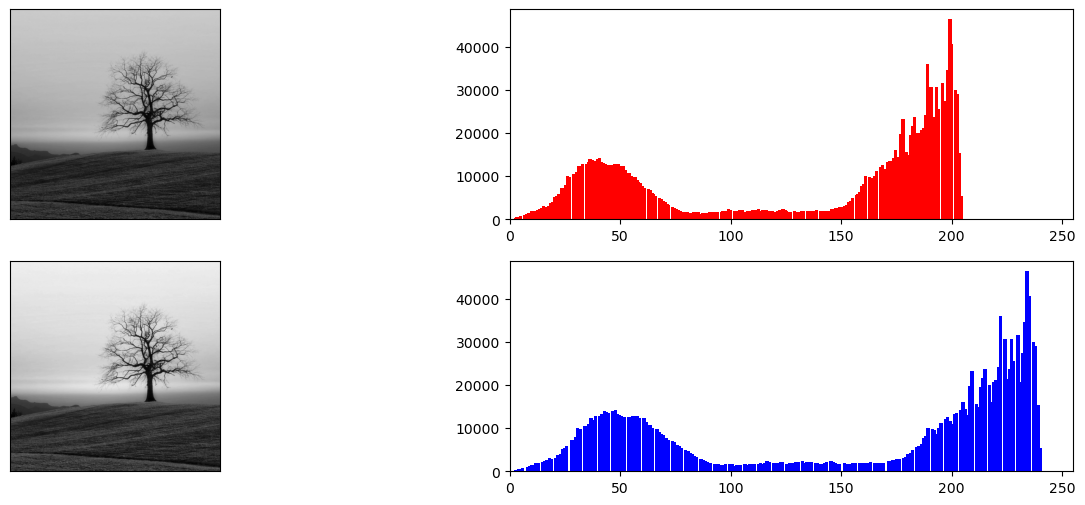

[[235.02304147 235.02304147 235.02304147 ... 233.84792627 235.02304147
  235.02304147]
 [235.02304147 235.02304147 235.02304147 ... 233.84792627 233.84792627
  235.02304147]
 [233.84792627 233.84792627 233.84792627 ... 233.84792627 233.84792627
  233.84792627]
 ...
 [ 62.28110599  69.33179724  74.03225806 ...  51.70506912  37.60368664
   36.42857143]
 [ 68.15668203  74.03225806  76.38248848 ...  54.05529954  36.42857143
   39.95391705]
 [ 55.23041475  59.93087558  61.10599078 ...  56.40552995  43.47926267
   50.52995392]]


In [42]:
image = cv2.imread('C:/Users/Abror/Desktop/img.png', 0)
hist_img = np.histogram(image, bins=256)

stretched = 255 / (np.amax(image) - np.amin(image)) * (image - np.amin(image))
hist_strch = np.histogram(stretched, bins=256)

plt.figure(figsize=(16, 6))
plt.subplot(221), plt.xticks([]), plt.yticks([])
plt.imshow(image, cmap='gray', vmin=0, vmax=255)

plt.subplot(222), plt.xlim([0, 255])
plt.bar(hist_img[1][1:], hist_img[0], color='red', width=1.5)

plt.subplot(223), plt.xticks([]), plt.yticks([])
plt.imshow(stretched, cmap='gray', vmin=0, vmax=255)

plt.subplot(224), plt.xlim([0, 255])
plt.bar(hist_strch[1][1:], hist_strch[0], color='blue', width=1.5)

plt.show()

print(stretched)

In [44]:
mri_img = cv2.imread('C:/Users/Abror/Desktop/img.png', 0)
cameraman_img = cv2.imread('C:/Users/Abror/Desktop/image.webp', 0)
pout_img = cv2.imread('C:/Users/Abror/Desktop/images.jpg', 0)

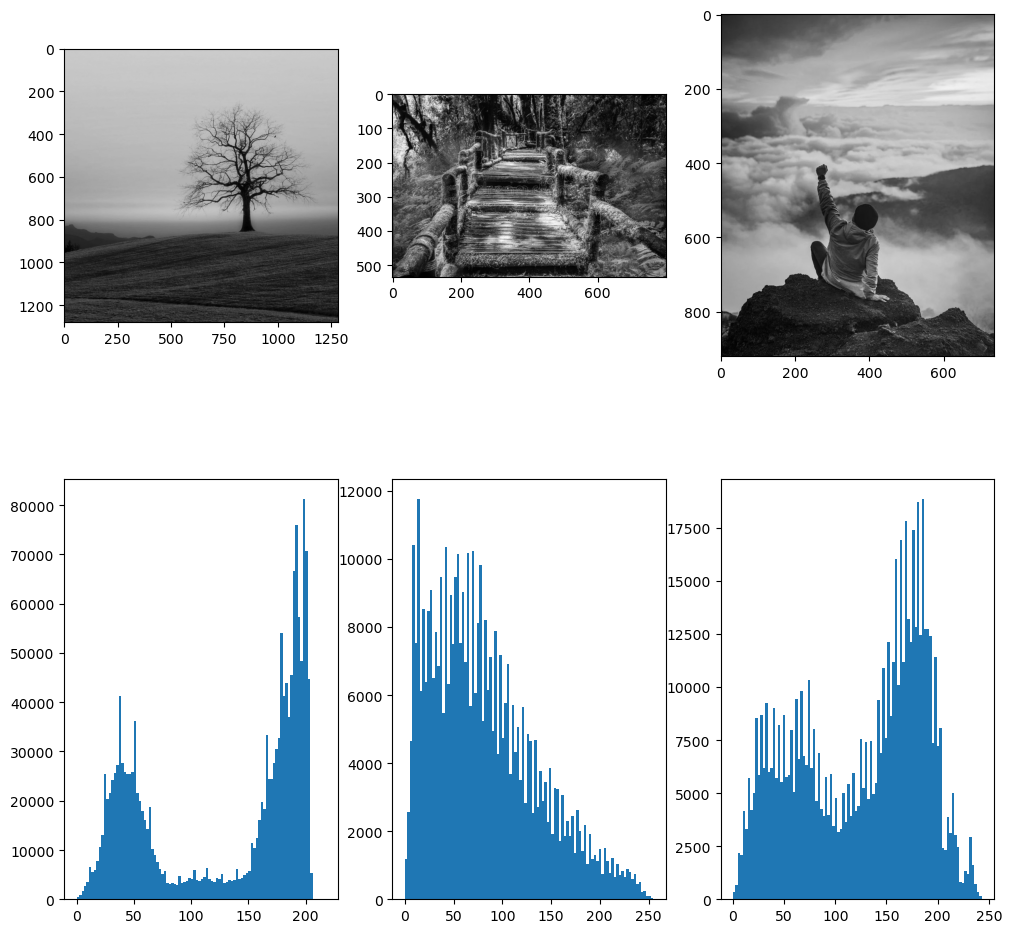

In [45]:
plt.figure(figsize=(12, 12))

plt.subplot(231), plt.imshow(mri_img, cmap='gray', vmin=0, vmax=255)
plt.subplot(234), plt.hist(mri_img.ravel(), bins=100)

plt.subplot(232), plt.imshow(cameraman_img, cmap='gray', vmin=0, vmax=255)
plt.subplot(235), plt.hist(cameraman_img.ravel(), bins=100)

plt.subplot(233), plt.imshow(pout_img, cmap='gray', vmin=0, vmax=255)
plt.subplot(236), plt.hist(pout_img.ravel(), bins=100)

plt.show()

In [46]:
def histogramEqualization(f, bins=100):
    his, be = np.histogram(f, bins=bins)
    his = his.astype(float)/sum(his)
    return np.interp(f, be, np.hstack((np.zeros((1)), np.cumsum(his))))

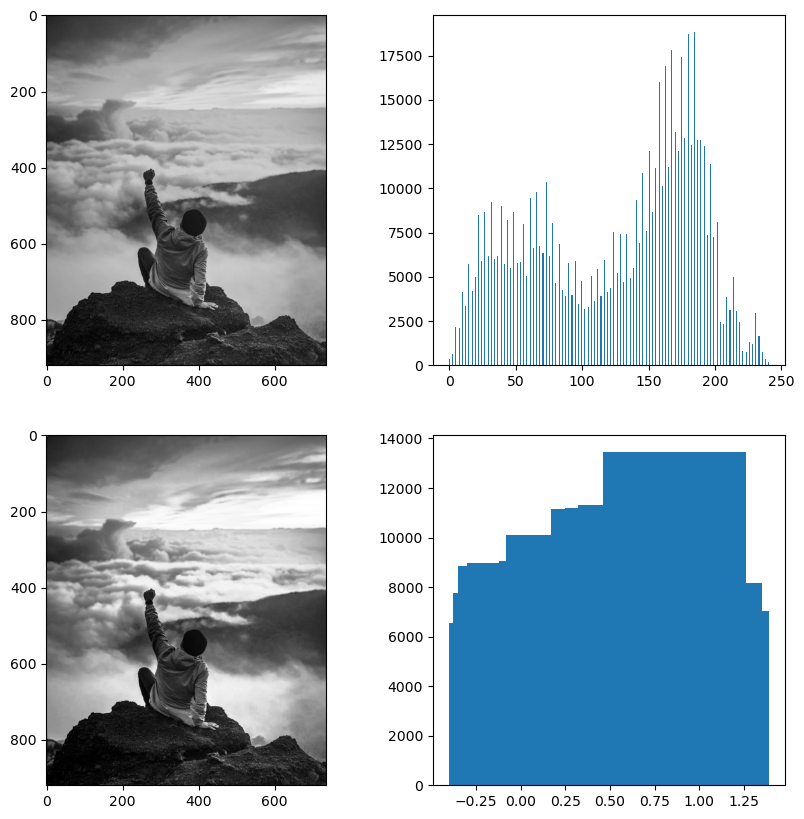

In [47]:
image = pout_img

plt.figure(figsize=(10, 10))

plt.subplot(221), plt.imshow(image, cmap='gray', vmin=0, vmax=255)
histo, range = np.histogram(image, bins=100)
plt.subplot(222), plt.bar(range[:-1], histo)

Eq = histogramEqualization(image)
plt.subplot(223), plt.imshow(Eq, cmap='gray')
histo, range = np.histogram(Eq, bins=100)
plt.subplot(224), plt.bar(range[:-1], histo)

plt.show()

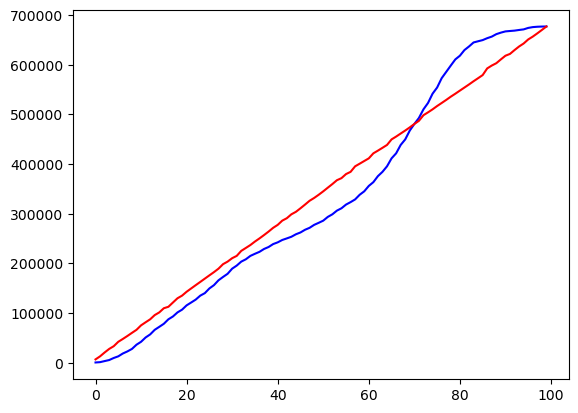

In [49]:
image = pout_img
histo, range = np.histogram(image, bins=100)
cdf_1 = np.cumsum(histo)

Eq = histogramEqualization(image)
histo, range = np.histogram(Eq, bins=100)
cdf_2 = np.cumsum(histo)

plt.figure()
plt.plot(cdf_1, 'b')
plt.plot(cdf_2, 'r')
plt.show()
     

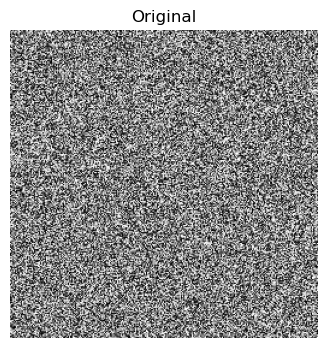

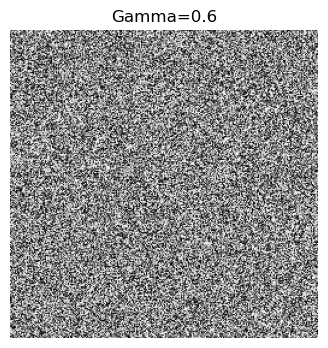

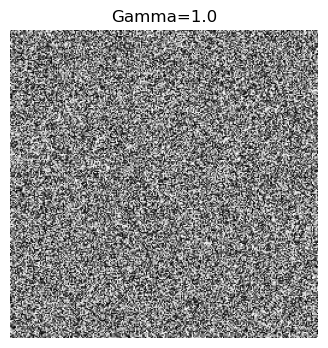

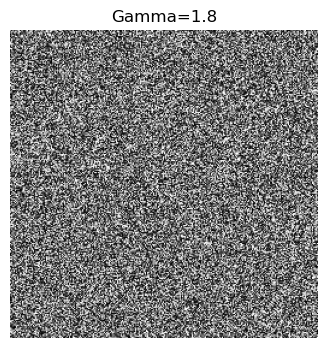

In [53]:

def apply_gamma(img, gamma):
    img = img.astype(np.float32) / 255.0
    out = np.power(img, gamma)
    return np.uint8(np.clip(out*255.0, 0, 255))
    
img = cv2.imread('C:/Users/Abror/Desktop/img.png', cv2.IMREAD_GRAYSCALE)

img = np.uint8(np.clip(60 + 80*np.random.rand(256,256), 0, 255))

g1 = apply_gamma(img, 0.6)
g2 = apply_gamma(img, 1.0)
g3 = apply_gamma(img, 1.8)

show(img, "Original", cmap="gray")
show(g1, "Gamma=0.6", cmap="gray")
show(g2, "Gamma=1.0", cmap="gray")
show(g3, "Gamma=1.8", cmap="gray")